# 6. Proximity Search: chỉ mục lưới tự cài + Haversine

Tìm các điểm học (POI) quanh vị trí người học (`BE/apps/algorithms/proximity.py`):

1. Mỗi POI vào ô lưới (⌊lat/Δ⌋, ⌊lng/Δ⌋), Δ = 0,01° (~1,1 km).
2. Truy vấn (lat, lng, r): chỉ duyệt các ô giao với hình chữ nhật bao đường tròn
   (Δlat = r / 111 320 m, Δlng = r / (111 320 m · cos lat)).
3. Tính khoảng cách đúng bằng Haversine cho các ứng viên, giữ d ≤ r, sắp xếp.

Chi phí O(số ô + số ứng viên) thay vì O(N). Đối chứng: quét toàn bộ (brute force) và PostgreSQL earthdistance.

> **Cách chạy:** mở bằng VS Code (hoặc Jupyter), chọn kernel **LingoPrism (BE venv)** rồi *Run All*. PostgreSQL phải đang chạy. Notebook dùng đúng mã nguồn của server (`BE/apps/algorithms`), kết quả được lưu vào database nên trang **Admin → Thuật toán AI** hiện ngay kết quả mới nhất. Mọi biểu đồ được lưu thêm thành ảnh PNG trong `AI/notebooks/figures/` để đưa vào báo cáo.

In [1]:
# Khởi tạo: nạp Django của BE/ (database + mã thuật toán thật của server) và matplotlib
import pathlib, sys
_here = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "AI/notebooks/lingoprism_setup.py").exists())
sys.path.insert(0, str(_here / "AI/notebooks"))
from lingoprism_setup import ROOT, init, save, table
init()

import random, time
import numpy as np
import matplotlib.pyplot as plt

Django OK – config.settings.dev | hình lưu ở D:\kicuoi\doantotnghiep\SnapLingua-main\AI\notebooks\figures


In [2]:
QUERIES = 500

from apps.algorithms import experiments
from apps.algorithms.proximity import CELL_DEG, M_PER_DEG_LAT, GridIndex, brute_force, haversine

d = haversine(21.0245, 105.8576, 21.0287, 105.8523)
print(f"Nhà hát Lớn Hà Nội → Tháp Rùa: {d:.0f} m")

Nhà hát Lớn Hà Nội → Tháp Rùa: 722 m


## 6.1 Minh hoạ chỉ mục lưới

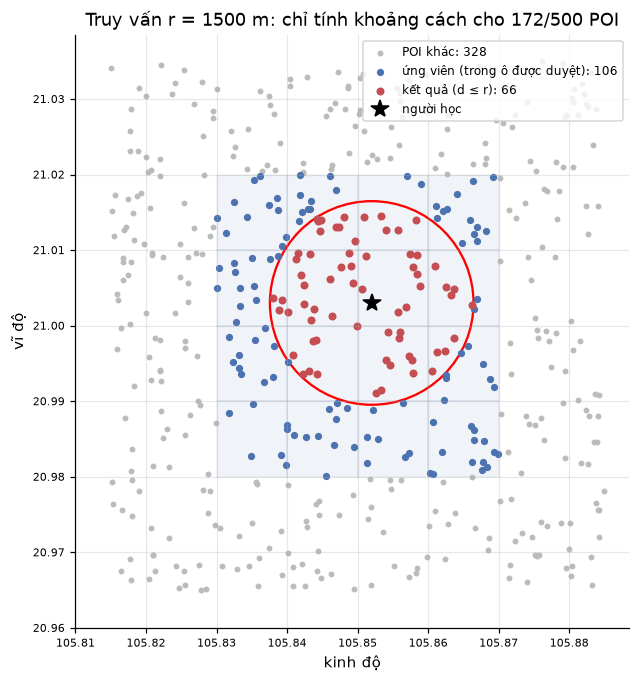

In [3]:
import matplotlib.patches as mp

rng = random.Random(0)
pts = [(i, 21.0 + rng.uniform(-0.035, 0.035), 105.85 + rng.uniform(-0.035, 0.035)) for i in range(500)]
idx = GridIndex(pts)
lat, lng, r = 21.003, 105.852, 1500
hits = {p for p, _ in idx.query(lat, lng, r)}
dlat, dlng = r / M_PER_DEG_LAT, r / (M_PER_DEG_LAT * np.cos(np.radians(lat)))
i0, j0 = idx._key(lat - dlat, lng - dlng)
i1, j1 = idx._key(lat + dlat, lng + dlng)
cand = {p for i in range(i0, i1 + 1) for j in range(j0, j1 + 1) for p, _, _ in idx.cells.get((i, j), ())}

fig, ax = plt.subplots(figsize=(7, 7))
for i in range(i0, i1 + 1):
    for j in range(j0, j1 + 1):
        ax.add_patch(mp.Rectangle((j * CELL_DEG, i * CELL_DEG), CELL_DEG, CELL_DEG, color="#4c72b0", alpha=0.08))
ax.add_patch(mp.Ellipse((lng, lat), 2 * dlng, 2 * dlat, fill=False, color="red", lw=1.5))
for name, sel, c, s in (("POI khác", lambda p: p not in cand, "#bbb", 8), ("ứng viên (trong ô được duyệt)", lambda p: p in cand and p not in hits, "#4c72b0", 14),
                        ("kết quả (d ≤ r)", lambda p: p in hits, "#c44e52", 18)):
    xs = [(b, a) for p, a, b in pts if sel(p)]
    ax.scatter([x for x, _ in xs], [y for _, y in xs], s=s, c=c, label=f"{name}: {len(xs)}")
ax.plot(lng, lat, "k*", ms=12, label="người học")
ax.set_xticks(np.arange(105.81, 105.89, CELL_DEG)); ax.set_yticks(np.arange(20.96, 21.04, CELL_DEG))
ax.tick_params(labelsize=7)
ax.ticklabel_format(useOffset=False)
ax.set_xlabel("kinh độ"); ax.set_ylabel("vĩ độ")
ax.set_title(f"Truy vấn r = {r} m: chỉ tính khoảng cách cho {len(cand)}/{len(pts)} POI")
ax.legend(loc="upper right", fontsize=8)
ax.set_aspect(1 / np.cos(np.radians(lat)))
save(fig, "06_luoi_minh_hoa")
plt.show()
assert hits == {p for p, _ in brute_force(pts, lat, lng, r)}

## 6.2 Độ chính xác và tốc độ trên POI thật + dữ liệu tổng hợp

30 POI thật, 500 truy vấn – 1s
lưới = brute force: 500/500 | lưới = PostgreSQL: 499/500 | lệch khoảng cách tối đa so với PostgreSQL: 11.224 m
phương pháp               ms / truy vấn
------------------------  -------------
lưới + Haversine          0.0158       
brute force               0.0167       
PostgreSQL earthdistance  0.8310       

pois   grid_ms  brute_ms  speedup 
-----  -------  --------  --------
1000   0.0040   0.6480    179.3000
10000  0.0210   5.5680    269.9000
50000  0.1400   29.3760   209.3000


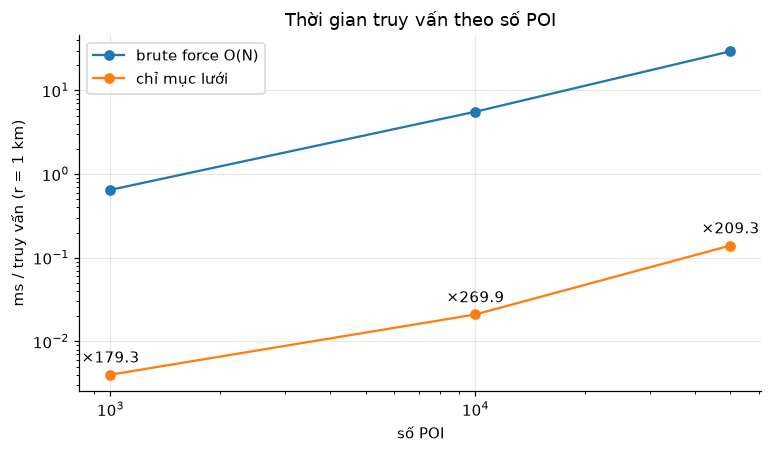

In [4]:
t0 = time.time()
run = experiments.proximity(QUERIES)
res = run.results
print(f"{res['pois']} POI thật, {res['queries']} truy vấn – {time.time() - t0:.0f}s")
print("lưới = brute force:", res["grid_equals_brute"], "| lưới = PostgreSQL:", res["grid_vs_postgres_ids"],
      f"| lệch khoảng cách tối đa so với PostgreSQL: {res['max_distance_diff_m']} m")
table([{"phương pháp": "lưới + Haversine", "ms / truy vấn": res["grid_ms"]},
       {"phương pháp": "brute force", "ms / truy vấn": res["brute_ms"]},
       {"phương pháp": "PostgreSQL earthdistance", "ms / truy vấn": res["postgres_ms"]}])
print()
table(res["scaling"])
sc = res["scaling"]
fig, ax = plt.subplots()
ax.plot([s["pois"] for s in sc], [s["brute_ms"] for s in sc], marker="o", label="brute force O(N)")
ax.plot([s["pois"] for s in sc], [s["grid_ms"] for s in sc], marker="o", label="chỉ mục lưới")
for s in sc:
    ax.annotate(f"×{s['speedup']}", (s["pois"], s["grid_ms"]), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("số POI"); ax.set_ylabel("ms / truy vấn (r = 1 km)")
ax.set_title("Thời gian truy vấn theo số POI")
ax.legend()
save(fig, "06_toc_do")
plt.show()